#### **Importing Required Python libraries**

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

### **Load dataset**

In [2]:
dataset=pd.read_csv("/content/academic_success_dataset.csv")

### **Summarize data**

In [3]:
dataset

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP,Target,Unnamed: 25,Unnamed: 26
0,1.0,17.0,5.0,171.0,1.0,1.0,122.0,1.0,19.0,12.0,...,1.0,0.0,NaN,0.0,10.8,1.4,1.74,Dropout,NaN,NaN
1,1.0,15.0,1.0,9254.0,1.0,1.0,160.0,1.0,1.0,3.0,...,1.0,0.0,19.0,0.0,13.9,-0.3,0.79,Graduate,NaN,NaN
2,1.0,NaN,5.0,9070.0,1.0,1.0,122.0,NaN,37.0,37.0,...,1.0,NaN,19.0,0.0,10.8,1.4,1.74,Dropout,NaN,NaN
3,1.0,17.0,2.0,9773.0,1.0,1.0,122.0,1.0,38.0,37.0,...,NaN,0.0,20.0,0.0,9.4,-0.8,-3.12,Graduate,NaN,NaN
4,2.0,39.0,1.0,8014.0,0.0,1.0,100.0,1.0,37.0,NaN,...,0.0,0.0,NaN,0.0,13.9,-0.3,0.79,Graduate,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,NaN,1.0,6.0,9773.0,1.0,1.0,125.0,1.0,1.0,1.0,...,1.0,0.0,19.0,0.0,NaN,2.8,-4.06,NaN,NaN,NaN
4420,1.0,1.0,2.0,9773.0,1.0,1.0,120.0,105.0,1.0,1.0,...,0.0,0.0,18.0,1.0,11.1,0.6,2.02,Dropout,NaN,NaN
4421,1.0,1.0,1.0,9500.0,1.0,1.0,154.0,1.0,37.0,37.0,...,0.0,1.0,30.0,NaN,13.9,-0.3,0.79,Dropout,NaN,NaN
4422,1.0,1.0,1.0,9147.0,1.0,1.0,180.0,1.0,37.0,37.0,...,0.0,1.0,20.0,0.0,9.4,-0.8,-3.12,Graduate,NaN,NaN


In [4]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (4424, 27). This dataset contains 4424 rows and 27 columns.


### **Feature Names and its Datatypes**

In [5]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Marital status                  4001 non-null   float64
 1   Application mode                3941 non-null   float64
 2   Application order               3998 non-null   float64
 3   Course                          3959 non-null   float64
 4   Daytime/evening attendance	     3984 non-null   float64
 5   Previous qualification          3990 non-null   float64
 6   Previous qualification (grade)  3952 non-null   float64
 7   Nacionality                     3978 non-null   float64
 8   Mother's qualification          4010 non-null   float64
 9   Father's qualification          3974 non-null   float64
 10  Mother's occupation             3988 non-null   float64
 11  Father's occupation             3999 non-null   float64
 12  Admission grade                 39

####Droping column

In [6]:
dataset = dataset.drop(['Unnamed: 25', 'Unnamed: 26', 'Application order', 'Application mode' ], axis=1)

In [7]:
'''print("Shape of dataframe before dropping:", dataset.shape)

for col in dataset.columns:
    if dataset[col].isnull().sum() >= 450:
        dataset = dataset.dropna(axis=0, subset=[col])  # Drop rows where that column is null

print("Shape after dropping:", dataset.shape)'''

'print("Shape of dataframe before dropping:", dataset.shape)\n\nfor col in dataset.columns:\n    if dataset[col].isnull().sum() >= 450:\n        dataset = dataset.dropna(axis=0, subset=[col])  # Drop rows where that column is null\n\nprint("Shape after dropping:", dataset.shape)'

In [8]:
'''print("Shape before dropping columns:", dataset.shape)

# Calculate threshold: keep columns with at least 60% non-null data
threshold = len(dataset) * 0.5
dataset = dataset.dropna(axis=1, thresh=threshold)

print("Shape after dropping columns:", dataset.shape)'''

'print("Shape before dropping columns:", dataset.shape)\n\n# Calculate threshold: keep columns with at least 60% non-null data\nthreshold = len(dataset) * 0.5\ndataset = dataset.dropna(axis=1, thresh=threshold)\n\nprint("Shape after dropping columns:", dataset.shape)'

### **Data Spliting**
#### Select and separately store Numerical and Categorical features in different variables.

In [9]:
##Selecting numerical features
numerical_data = dataset.select_dtypes(include='number')

#append the features of numerical_data to list
numerical_features=numerical_data.columns.tolist()

print(f'There are {len(numerical_features)} numerical features:', '\n')
print(numerical_features)

There are 22 numerical features: 

['Marital status', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']


In [10]:
#Selecting categoricalfeatures
categorical_data=dataset.select_dtypes(include= 'object')

#append the features of categorical_data to list
categorical_features=categorical_data.columns.tolist()

print(f'There are {len(categorical_features)} categorical features:', '\n')
print(categorical_features)

There are 1 categorical features: 

['Target']


###Removing Null values / Handling Missing data

In [11]:
dataset.isnull().sum()

,0
Marital status,423
Course,465
Daytime/evening attendance\t,440
Previous qualification,434
Previous qualification (grade),472
Nacionality,446
Mother's qualification,414
Father's qualification,450
Mother's occupation,436
Father's occupation,425


In [12]:
#For numaric type data
print("Shape of dataframe before dropping:", dataset.shape)
for col in dataset.columns:
    if col in numerical_features and dataset[col].isnull().sum() >= 450:
      dataset = dataset.dropna(axis=0, subset=[col])  # Drop rows where that column is null
    elif col in numerical_features:
        dataset[col] = dataset[col].fillna(dataset[col].mean())
print("Shape of dataframe after dropping:", dataset.shape)

Shape of dataframe before dropping: (4424, 23)
Shape of dataframe after dropping: (3959, 23)


In [13]:
dataset.isnull().sum()

,0
Marital status,0
Course,0
Daytime/evening attendance\t,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0
Father's occupation,0


In [14]:
#For catagorical type data
print("Shape of dataframe before dropping:", dataset.shape)
dataset = dataset.dropna(axis=0, subset=[col])  # Drop rows where that column is null
print("Shape of dataframe before dropping:", dataset.shape)

Shape of dataframe before dropping: (3959, 23)
Shape of dataframe before dropping: (3541, 23)


In [15]:
dataset.isnull().sum()

,0
Marital status,0
Course,0
Daytime/evening attendance\t,0
Previous qualification,0
Previous qualification (grade),0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0
Father's occupation,0


In [16]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 3541 entries, 0 to 4423
Data columns (total 23 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Marital status                  3541 non-null   float64
 1   Course                          3541 non-null   float64
 2   Daytime/evening attendance	     3541 non-null   float64
 3   Previous qualification          3541 non-null   float64
 4   Previous qualification (grade)  3541 non-null   float64
 5   Nacionality                     3541 non-null   float64
 6   Mother's qualification          3541 non-null   float64
 7   Father's qualification          3541 non-null   float64
 8   Mother's occupation             3541 non-null   float64
 9   Father's occupation             3541 non-null   float64
 10  Admission grade                 3541 non-null   float64
 11  Displaced                       3541 non-null   float64
 12  Educational special needs       3541 no

In [17]:
print ('Shape of the dataset is {}. This dataset contains {} rows and {} columns.'.format(dataset.shape,dataset.shape[0],dataset.shape[1]))

Shape of the dataset is (3541, 23). This dataset contains 3541 rows and 23 columns.


### **Descriptive Analysis**
#### In descriptive Analysis we analysis each variable separately to get inference about the feature.
### **Summary satistics of Numerical Features**

In [18]:
# Transposed stats for numerical features

numerical_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Marital status,4001.0,1.172457,0.584595,1.00,1.0,1.00,1.00,6.00
Course,3959.0,8856.628947,2063.151599,33.00,9085.0,9238.00,9556.00,9991.00
Daytime/evening attendance\t,3984.0,0.892319,0.310016,0.00,1.0,1.00,1.00,1.00
Previous qualification,3990.0,4.525564,10.132748,1.00,1.0,1.00,1.00,43.00
Previous qualification (grade),3952.0,132.690056,13.226582,95.00,125.0,133.10,140.00,190.00
Nacionality,3978.0,1.860985,7.040422,1.00,1.0,1.00,1.00,109.00
Mother's qualification,4010.0,19.482294,15.620541,1.00,2.0,19.00,37.00,44.00
Father's qualification,3974.0,22.203070,15.382146,1.00,3.0,19.00,37.00,44.00
Mother's occupation,3988.0,10.895687,26.304799,0.00,4.0,5.00,9.00,194.00
Father's occupation,3999.0,10.910978,25.003303,0.00,4.0,7.00,9.00,194.00


In [19]:
categorical_data.describe().T

,count,unique,top,freq
Target,3971,3,Graduate,1979


### **Variance of each numerical features**

In [20]:
numerical_data.var()

,0
Marital status,3.417512e-01
Course,4.256595e+06
Daytime/evening attendance\t,9.610971e-02
Previous qualification,1.026726e+02
Previous qualification (grade),1.749425e+02
Nacionality,4.956754e+01
Mother's qualification,2.440013e+02
Father's qualification,2.366104e+02
Mother's occupation,6.919425e+02
Father's occupation,6.251652e+02


In [21]:
numerical_data.skew()

,0
Marital status,4.429740
Course,-3.808295
Daytime/evening attendance\t,-2.532235
Previous qualification,2.900447
Previous qualification (grade),0.307966
Nacionality,10.924248
Mother's qualification,0.010805
Father's qualification,-0.291581
Mother's occupation,5.383512
Father's occupation,5.488079


/tmp/ipython-input-3388148556.py:15: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


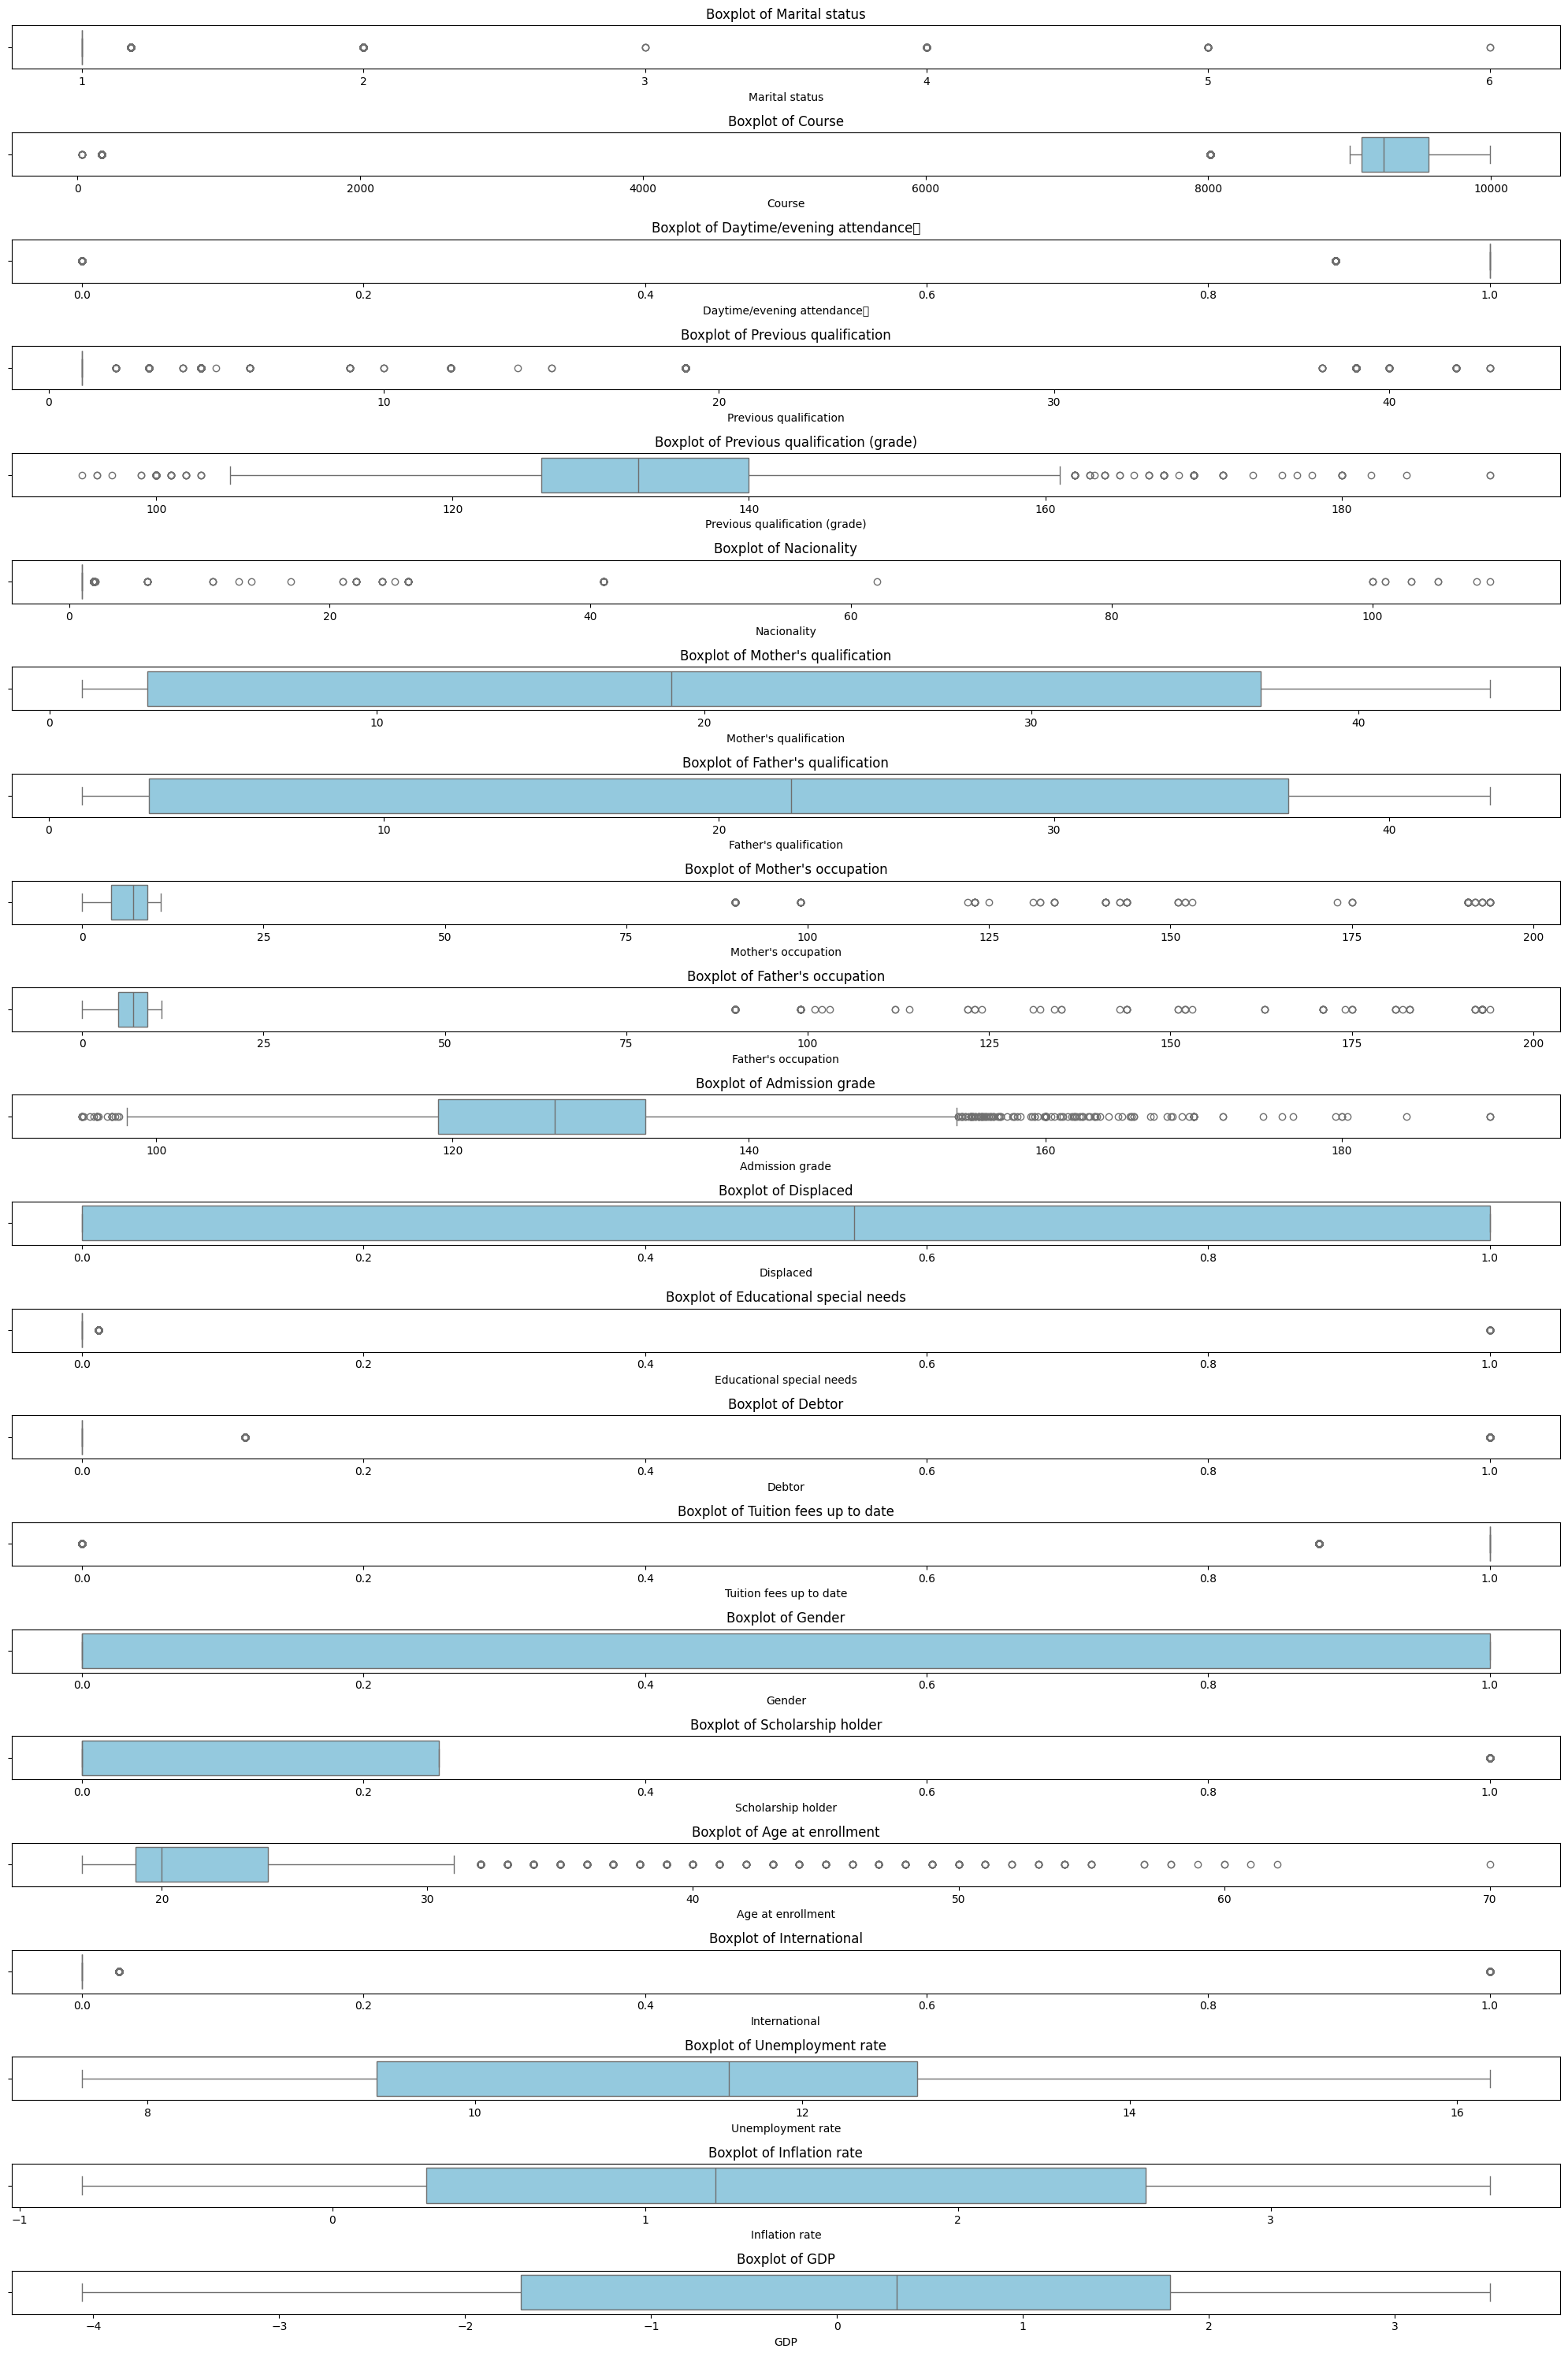

In [22]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only numerical columns for boxplot analysis
numeric_cols = dataset.select_dtypes(include=['int64', 'float64']).columns

# Set up the figure
plt.figure(figsize=(20, 30))

# Plot boxplots for each numerical feature including the target variable 'OUTCOME'
for i, col in enumerate(numeric_cols, 1):
    plt.subplot(len(numeric_cols), 1, i)
    sns.boxplot(x=dataset[col], color='skyblue')
    plt.title(f'Boxplot of {col}', fontsize=12)
    plt.tight_layout()

plt.show()


### **Number Unique values in each feature**

In [23]:
numerical_data.nunique()

,0
Marital status,6
Course,17
Daytime/evening attendance\t,2
Previous qualification,17
Previous qualification (grade),98
Nacionality,20
Mother's qualification,28
Father's qualification,34
Mother's occupation,32
Father's occupation,43


### **Categorical Features**


#### **No of unique values in each categorical feature**

In [24]:
# unique values counts
unique_counts=categorical_data.nunique()
print(unique_counts)

Target    3
dtype: int64


### **Barplot of unique value counts in every categorical features**

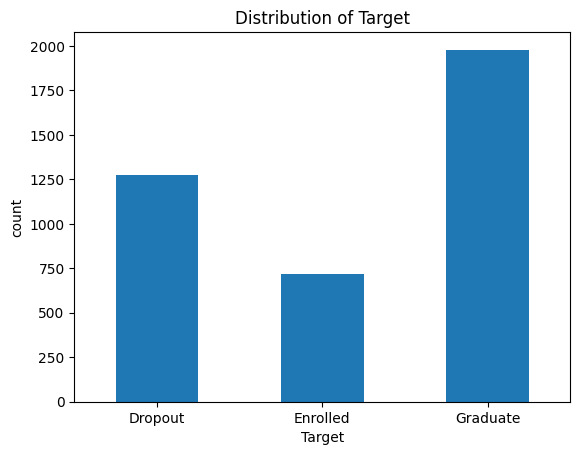

In [25]:
for col in categorical_features:
    plt.title(f'Distribution of {col}')
    categorical_data[col].value_counts().sort_index().plot(kind='bar', rot=0, xlabel=col,ylabel='count')
    plt.show()

### **Correlation Analysis**
### **Correlation matrix of whole dataset**

In [26]:
# Calculate the correlation matrix
correlation_matrix = numerical_data.corr()
correlation_matrix


,Marital status,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,...,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Unemployment rate,Inflation rate,GDP
Marital status,1.000000,0.049238,-0.249639,0.064128,-0.012464,-0.000230,0.193717,0.128422,0.042128,0.030536,...,-0.028061,0.021323,-0.085866,-0.019408,-0.058398,0.519273,-0.024565,-0.026655,0.010249,-0.031970
Course,0.049238,1.000000,-0.043596,0.006595,-0.082613,-0.014590,0.060951,0.053140,0.027489,0.028383,...,-0.030587,-0.037873,0.021956,-0.093058,0.026010,0.043035,-0.033084,0.004079,0.022479,-0.014133
Daytime/evening attendance\t,-0.249639,-0.043596,1.000000,-0.076964,0.037828,0.017786,-0.194607,-0.136796,-0.007505,-0.004237,...,0.031488,0.011800,0.035782,-0.010374,0.100069,-0.461294,0.028053,0.059635,-0.030558,0.032829
Previous qualification,0.064128,0.006595,-0.076964,1.000000,0.111794,-0.025856,-0.017178,0.001447,0.001885,-0.005957,...,-0.015677,0.083518,-0.066140,0.080861,-0.066096,0.153007,-0.029875,0.117137,-0.053671,0.060448
Previous qualification (grade),-0.012464,-0.082613,0.037828,0.111794,1.000000,0.067662,-0.041136,-0.030404,0.001689,-0.029708,...,-0.007453,-0.028762,0.069195,-0.047786,0.059792,-0.111009,0.056961,0.048658,0.026294,-0.053057
Nacionality,-0.000230,-0.014590,0.017786,-0.025856,0.067662,1.000000,-0.059092,-0.084323,0.021118,0.016367,...,-0.004979,0.046341,-0.021690,-0.026413,-0.017508,-0.009084,0.789915,0.004351,-0.016999,0.033080
Mother's qualification,0.193717,0.060951,-0.194607,-0.017178,-0.041136,-0.059092,1.000000,0.539903,0.087360,0.068588,...,-0.015047,0.025531,-0.014264,-0.058302,0.034311,0.292361,-0.037642,-0.110894,0.048168,-0.082145
Father's qualification,0.128422,0.053140,-0.136796,0.001447,-0.030404,-0.084323,0.539903,1.000000,0.061559,0.060407,...,0.013718,-0.007186,-0.010726,-0.080016,0.120818,0.195806,-0.078074,-0.080264,0.049515,-0.076036
Mother's occupation,0.042128,0.027489,-0.007505,0.001885,0.001689,0.021118,0.087360,0.061559,1.000000,0.918895,...,0.004665,0.115535,-0.014608,-0.000331,-0.017200,0.054000,0.014286,-0.081645,0.019204,0.117819
Father's occupation,0.030536,0.028383,-0.004237,-0.005957,-0.029708,0.016367,0.068588,0.060407,0.918895,1.000000,...,0.005982,0.098337,0.000683,-0.013709,-0.009642,0.022592,0.035380,-0.088516,0.033609,0.130394


### **Correlation Heatmap plot of whole dataset**

/usr/local/lib/python3.12/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


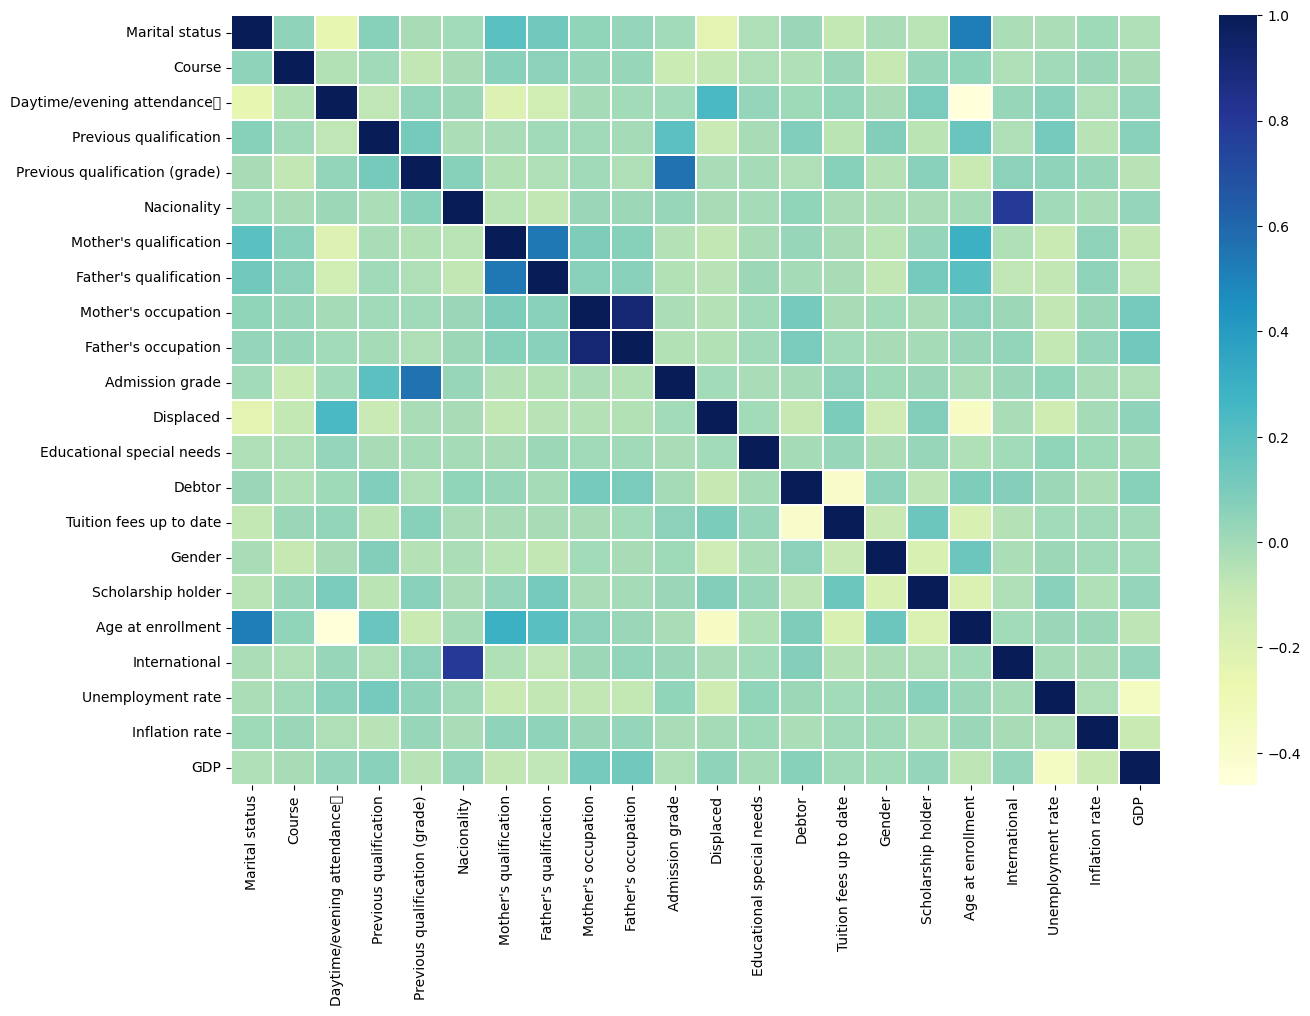

In [27]:
# Plotting the heatmap for correlation matrix
plt.figure(figsize=(15, 10))
sns.heatmap(correlation_matrix, cmap='YlGnBu', linewidths=0.3)
plt.show()

In [28]:
dataset['Target'] = dataset['Target'].map({'Dropout': 0, 'Enrolled': 1, 'Graduate': 2})

### **Check imbalance in the data**
#### We have classification problem so we need to check the balance of the given data.

In [29]:
#check Imbalance in data

#group instances based on the classes in OUTCOME variable
class_counts=dataset.groupby("Target").size()

columns=['outcome','count','percentage']
outcome=[0,1, 2]
count=list()
percentage=list()
total = len(dataset)
#Calculate the percentage of each value of the OUTCOME variable from total
for val in range(3):
    count.append(class_counts[val])
    percent=(class_counts[val]/total)*100
    percentage.append(percent)

# Convert the calulated values into a dataframe
imbalance_df=pd.DataFrame(list(zip(outcome,count,percentage)),columns=columns)
imbalance_df

,outcome,count,percentage
0,0,1163,32.843829
1,1,624,17.622141
2,2,1754,49.534030


### **Barplot of Outcome vs Percentage**

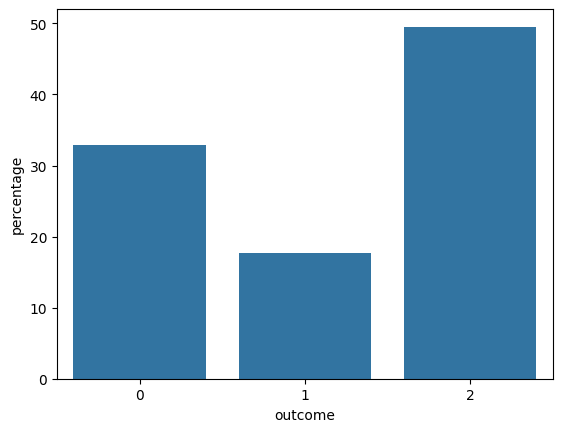

In [30]:
sns.barplot(data=imbalance_df,x=imbalance_df['outcome'],y=imbalance_df['percentage'])
plt.show()

### **Observation**
Around 55% of students are Graduates (2)

Around 29% are Dropouts (0)

Only 16% are still Enrolled (1)

The dataset shows a clear class imbalance, with Graduates being the majority class.

### **Data visualization**
#### Some other visualizations of features to get more insights

### **Density plots of numerical features**

/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


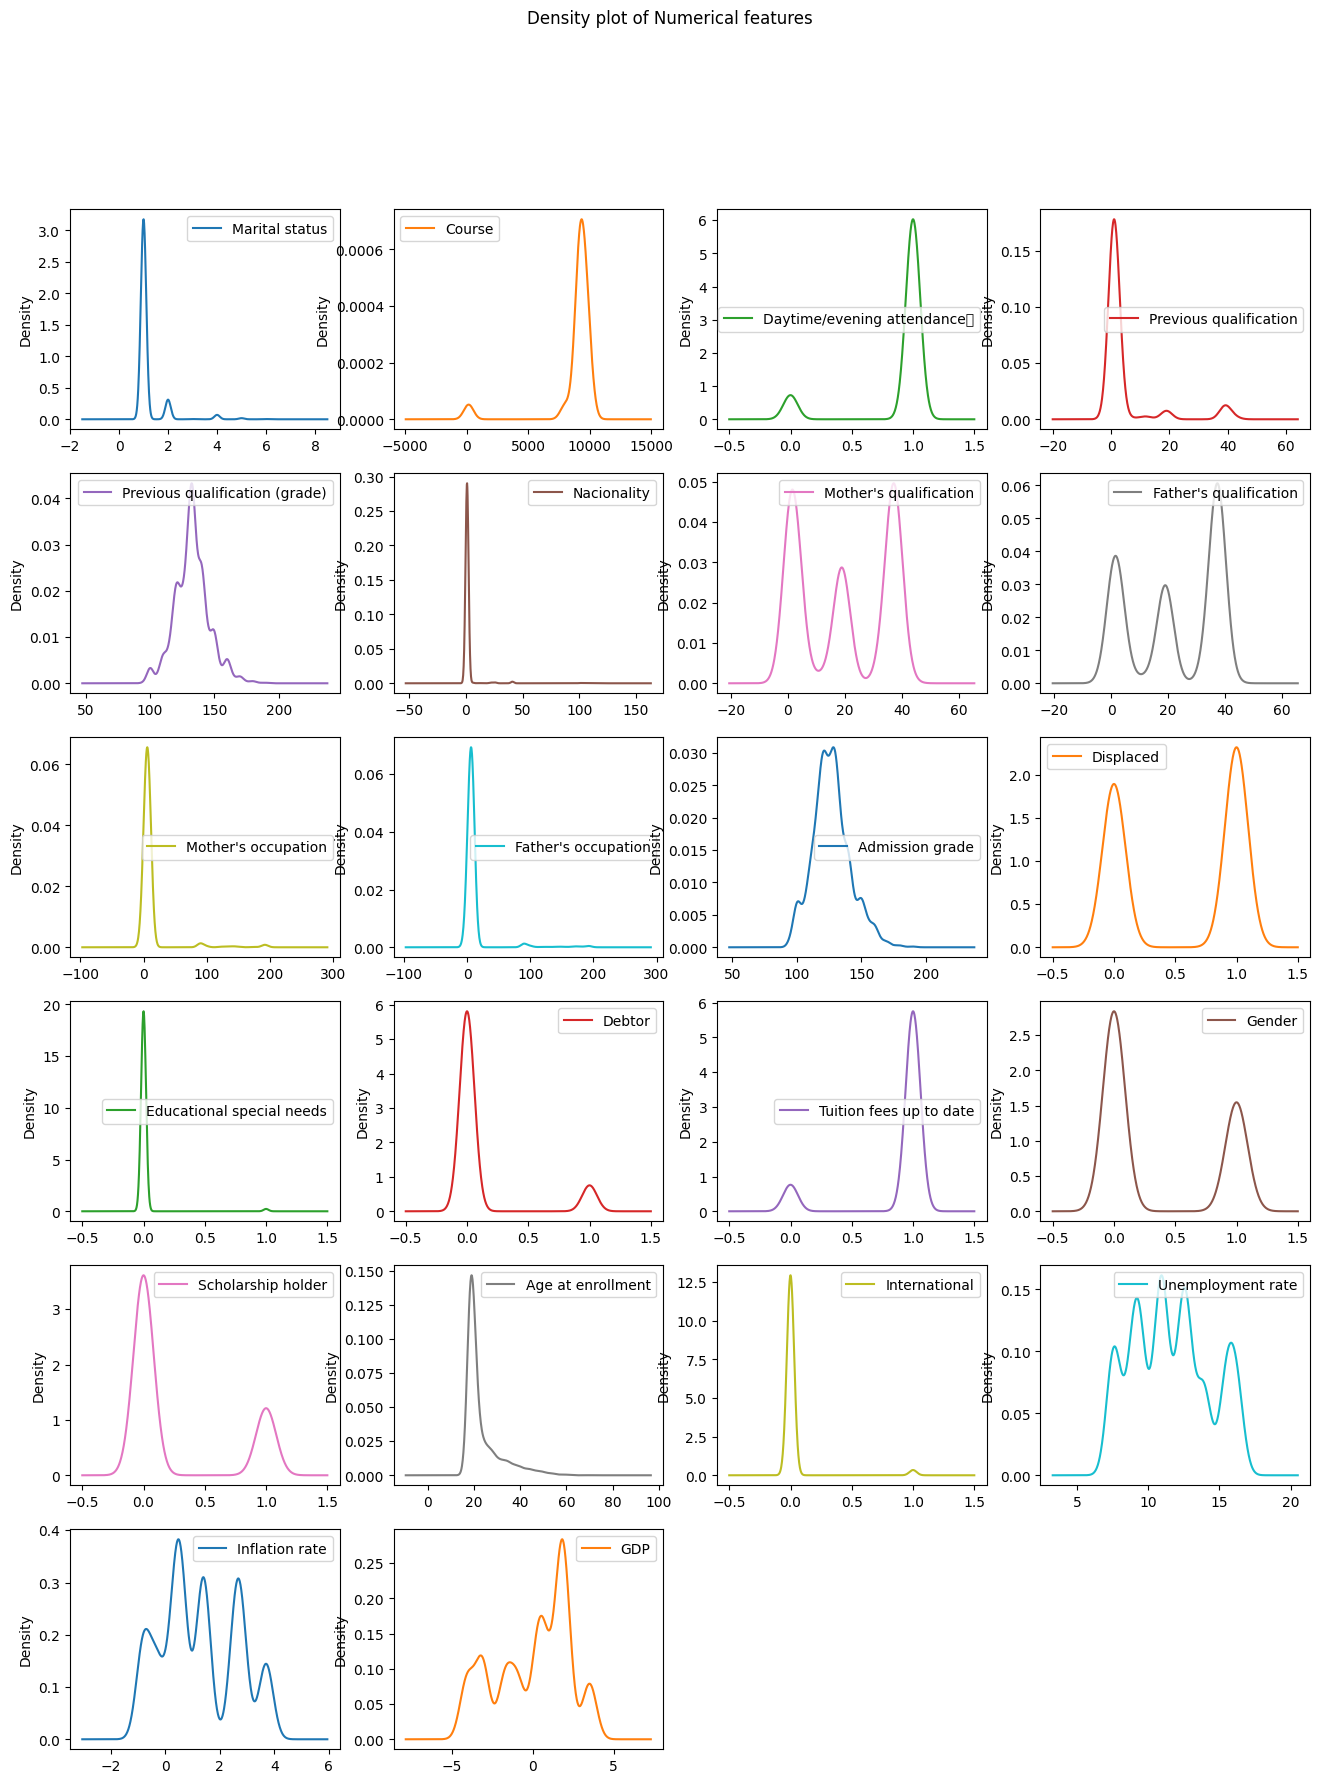

In [31]:
numerical_data.plot(kind='density',figsize=(16,20),subplots=True,layout=(6,4),title="Density plot of Numerical features",sharex=False)
plt.show()

## Define features and target

In [32]:

X = dataset.drop(['Target'], axis=1)
y = dataset['Target']


###Train-Test Split & Feature Scaling with StandardScaler

In [33]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split into train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Scale for better model performance
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


##Train Multiple Models

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    confusion_matrix, classification_report
)


###Train Model result

Compute ROC & AUC and Plot $ Multiclass Confusion Matrix & Accuracy


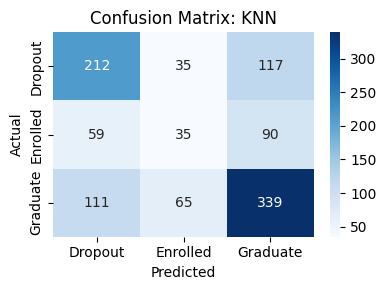

--- KNN Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.55      0.58      0.57       364
    Enrolled       0.26      0.19      0.22       184
    Graduate       0.62      0.66      0.64       515

    accuracy                           0.55      1063
   macro avg       0.48      0.48      0.48      1063
weighted avg       0.54      0.55      0.54      1063



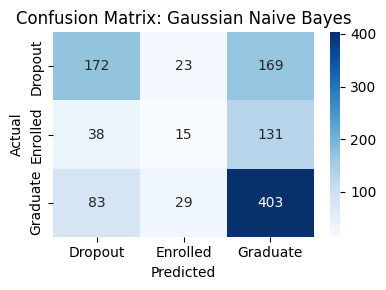

--- Gaussian Naive Bayes Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.59      0.47      0.52       364
    Enrolled       0.22      0.08      0.12       184
    Graduate       0.57      0.78      0.66       515

    accuracy                           0.56      1063
   macro avg       0.46      0.45      0.43      1063
weighted avg       0.52      0.56      0.52      1063



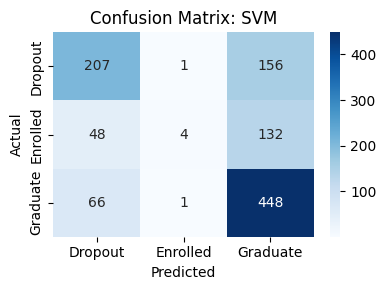

--- SVM Classification Report ---
              precision    recall  f1-score   support

     Dropout       0.64      0.57      0.60       364
    Enrolled       0.67      0.02      0.04       184
    Graduate       0.61      0.87      0.72       515

    accuracy                           0.62      1063
   macro avg       0.64      0.49      0.45      1063
weighted avg       0.63      0.62      0.56      1063



In [35]:
classifiers = {
    "KNN": KNeighborsClassifier(),
    "Gaussian Naive Bayes": GaussianNB(),
    "SVM": SVC(kernel='rbf', probability=True, random_state=42)
}

# STORAGE
clf_results = {}

for name, model in classifiers.items():
    # Train & Predict
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)


    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec  = recall_score(y_test, y_pred, average='weighted')
    clf_results[name] = {'accuracy': acc, 'precision': prec, 'recall': rec}


    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d',
                xticklabels=['Dropout','Enrolled','Graduate'],
                yticklabels=['Dropout','Enrolled','Graduate'],
                cmap='Blues')
    plt.title(f'Confusion Matrix: {name}')
    plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()


    print(f"--- {name} Classification Report ---")
    print(classification_report(
        y_test, y_pred,
        target_names=['Dropout','Enrolled','Graduate'],
        zero_division=0
    ))


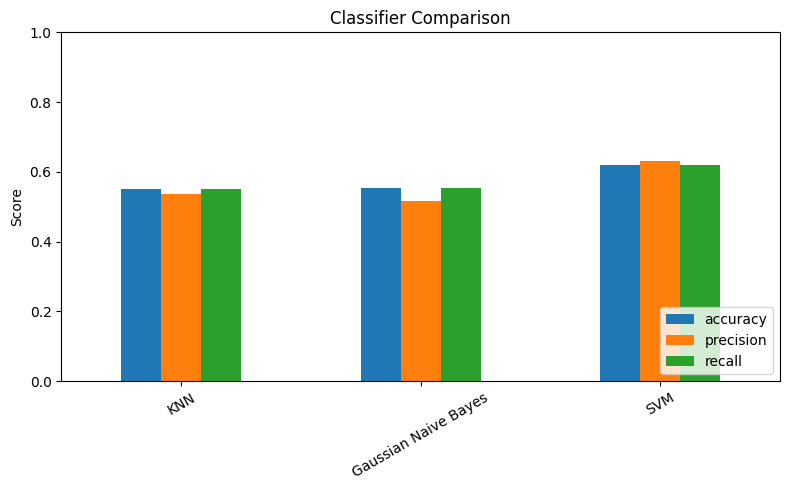

In [36]:
# ── 3) SUMMARY BARS ────────────────────────────────────────────────────────────
df_clf = pd.DataFrame(clf_results).T
df_clf[['accuracy','precision','recall']].plot(
    kind='bar', figsize=(8,5), rot=0, title='Classifier Comparison'
)
plt.ylabel('Score')
plt.ylim(0,1)
plt.xticks(rotation=30)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()